# Copper Virtual Foundry 3: sintered-density measurements

This first VF3 notebook contains the two available Archimedes measurements for specimen T17 after thermal cycle DS5 in an N+CO2 atmosphere. The analysis is descriptive because only one specimen is currently available. Factor effects, correlations, ANOVA, and Pareto analysis require additional specimens and are intentionally omitted.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from notebook_plot_saver import configure_notebook_plot_saving

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebook_plot_saver.py').exists():
    PROJECT_ROOT = PROJECT_ROOT / '3D_Printing_Project'

DATA_DIR = PROJECT_ROOT / 'doe_matrices' / 'Copper_VirtualFoundry3'
DATA_PATH = DATA_DIR / 'copper_virtualfoundry3_sintered_measurements.csv'
FIGURE_ROOT = configure_notebook_plot_saving(
    PROJECT_ROOT / 'notebook_figures',
    default_series='09_Copper_VirtualFoundry3',
)

plt.rcParams.update({
    'axes.titlesize': 17,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 12,
    'figure.titlesize': 21,
})

print(f'Data: {DATA_PATH.resolve()}')
print(f'Figures: {FIGURE_ROOT}')

Data: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\doe_matrices\Copper_VirtualFoundry3\copper_virtualfoundry3_sintered_measurements.csv
Figures: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


## Available measurements

The CSV is stored in long format: each row is one Archimedes measurement. New VF3 specimens can be added as additional rows without changing the analysis code.

In [2]:
measurements = pd.read_csv(DATA_PATH)
required_columns = {
    'Run', 'thermal_cycle', 'atmosphere', 'measurement',
    'weight_in_air_g', 'weight_in_water_g', 'volume_cm3',
    'sintered_density_g_cm3', 'sintered_relative_density_percent',
}
missing_columns = required_columns.difference(measurements.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')

numeric_columns = [
    'measurement', 'weight_in_air_g', 'weight_in_water_g', 'volume_cm3',
    'sintered_density_g_cm3', 'sintered_relative_density_percent',
]
measurements[numeric_columns] = measurements[numeric_columns].apply(
    pd.to_numeric, errors='raise'
)
measurements = measurements.sort_values(['Run', 'measurement']).reset_index(drop=True)
display(measurements.round(3))

,Run,thermal_cycle,atmosphere,measurement,weight_in_air_g,weight_in_water_g,volume_cm3,sintered_density_g_cm3,sintered_relative_density_percent
0,T17,DS5,N+CO2,1,39.26,5.47,5.48,7.16,79.96
1,T17,DS5,N+CO2,2,39.29,5.52,5.53,7.10,79.30


## Specimen summary

Standard deviations are sample standard deviations (`ddof=1`) across the repeated Archimedes measurements of each specimen. They describe measurement repeatability, not variation among printed specimens.

In [3]:
summary = (
    measurements.groupby(['Run', 'thermal_cycle', 'atmosphere'], as_index=False)
    .agg(
        n=('measurement', 'count'),
        mean_weight_in_air_g=('weight_in_air_g', 'mean'),
        mean_weight_in_water_g=('weight_in_water_g', 'mean'),
        mean_volume_cm3=('volume_cm3', 'mean'),
        mean_sintered_density_g_cm3=('sintered_density_g_cm3', 'mean'),
        sintered_density_sd_g_cm3=('sintered_density_g_cm3', 'std'),
        mean_sintered_relative_density_percent=(
            'sintered_relative_density_percent', 'mean'
        ),
        sintered_relative_density_sd_percentage_points=(
            'sintered_relative_density_percent', 'std'
        ),
    )
)
summary['density_measurement_range_g_cm3'] = measurements.groupby('Run')[
    'sintered_density_g_cm3'
].apply(lambda values: values.max() - values.min()).to_numpy()
display(summary.round(3))

t17 = summary.loc[summary['Run'].eq('T17')].iloc[0]
print(
    'T17 sintered density: '
    f"{t17['mean_sintered_density_g_cm3']:.2f} +/- "
    f"{t17['sintered_density_sd_g_cm3']:.2f} g/cm3 (n={int(t17['n'])})"
)
print(
    'T17 relative density: '
    f"{t17['mean_sintered_relative_density_percent']:.2f} +/- "
    f"{t17['sintered_relative_density_sd_percentage_points']:.2f} percentage points"
)

,Run,thermal_cycle,atmosphere,n,mean_weight_in_air_g,mean_weight_in_water_g,mean_volume_cm3,mean_sintered_density_g_cm3,sintered_density_sd_g_cm3,mean_sintered_relative_density_percent,sintered_relative_density_sd_percentage_points,density_measurement_range_g_cm3
0,T17,DS5,N+CO2,2,39.275,5.495,5.505,7.13,0.042,79.63,0.467,0.06


T17 sintered density: 7.13 +/- 0.04 g/cm3 (n=2)
T17 relative density: 79.63 +/- 0.47 percentage points


## Sintered density and relative density

Bars show the specimen mean, error bars show one sample standard deviation, and the lighter points show the individual Archimedes measurements.

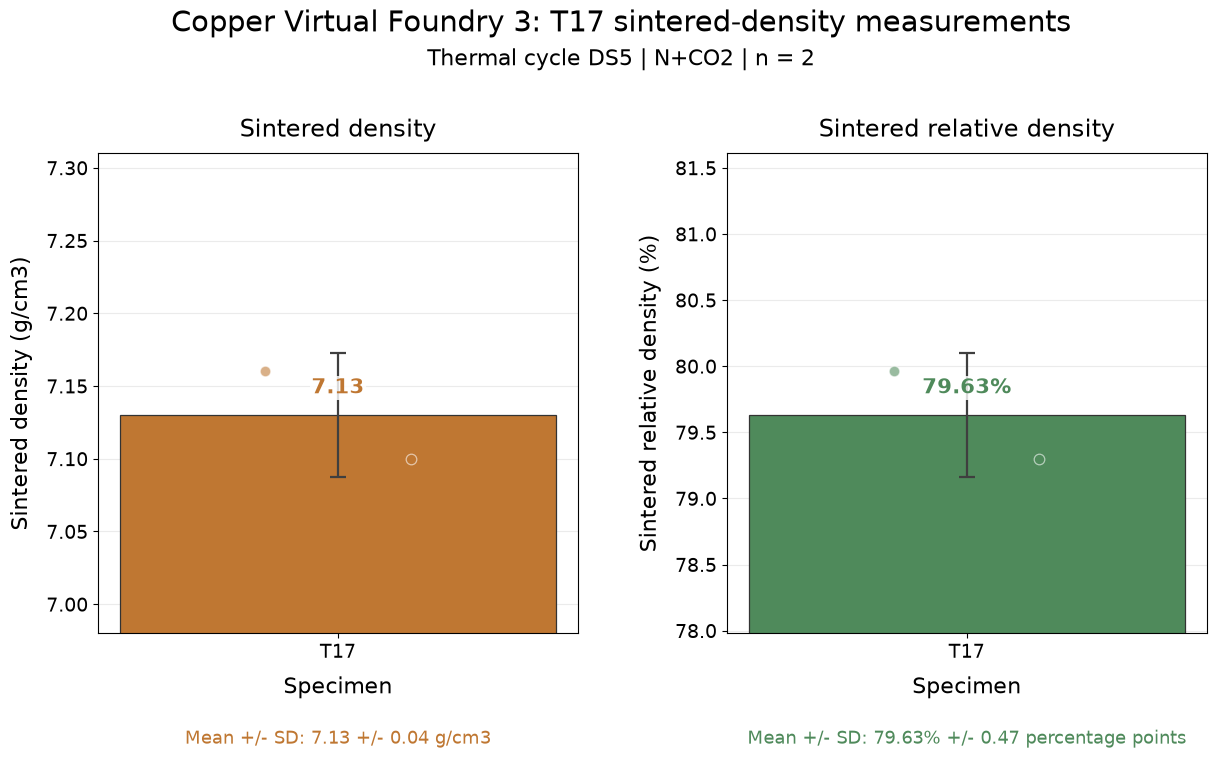

In [4]:
DENSITY_COLOR = '#bf7732'
RELATIVE_COLOR = '#4f8a5b'
ERROR_COLOR = '#3f3f3f'
VALUE_SIZE = 15

figure, axes = plt.subplots(1, 2, figsize=(12.5, 8.0))
plot_specs = [
    {
        'column': 'sintered_density_g_cm3',
        'mean': 'mean_sintered_density_g_cm3',
        'sd': 'sintered_density_sd_g_cm3',
        'color': DENSITY_COLOR,
        'title': 'Sintered density',
        'ylabel': 'Sintered density (g/cm3)',
        'format': lambda value: f'{value:.2f}',
    },
    {
        'column': 'sintered_relative_density_percent',
        'mean': 'mean_sintered_relative_density_percent',
        'sd': 'sintered_relative_density_sd_percentage_points',
        'color': RELATIVE_COLOR,
        'title': 'Sintered relative density',
        'ylabel': 'Sintered relative density (%)',
        'format': lambda value: f'{value:.2f}%',
    },
]

specimen_summary = summary.loc[summary['Run'].eq('T17')].copy()
specimen_measurements = measurements.loc[measurements['Run'].eq('T17')].copy()
positions = np.arange(len(specimen_summary), dtype=float)
for axis, spec in zip(axes, plot_specs):
    means = specimen_summary[spec['mean']].to_numpy(dtype=float)
    standard_deviations = specimen_summary[spec['sd']].fillna(0.0).to_numpy(dtype=float)
    bars = axis.bar(
        positions, means, width=0.48, color=spec['color'],
        edgecolor='#333333', linewidth=0.9, zorder=2,
    )
    axis.errorbar(
        positions, means, yerr=standard_deviations, fmt='none',
        ecolor=ERROR_COLOR, elinewidth=1.6, capsize=6, capthick=1.6, zorder=3,
    )

    for position, run in zip(positions, specimen_summary['Run']):
        values = specimen_measurements.loc[specimen_measurements['Run'].eq(run), spec['column']].to_numpy()
        offsets = np.linspace(-0.08, 0.08, len(values)) if len(values) > 1 else np.array([0.0])
        axis.scatter(
            position + offsets, values, s=58, color=spec['color'],
            edgecolor='white', linewidth=0.9, alpha=0.58, zorder=4,
        )

    all_values = specimen_measurements[spec['column']].to_numpy(dtype=float)
    data_span = max(all_values.max() - all_values.min(), standard_deviations.max(), 0.01)
    lower_margin = max(2.0 * data_span, 0.08 if spec['column'] == 'sintered_density_g_cm3' else 0.8)
    upper_margin = max(2.5 * data_span, 0.10 if spec['column'] == 'sintered_density_g_cm3' else 1.0)
    axis.set_ylim(all_values.min() - lower_margin, all_values.max() + upper_margin)
    label_offset = 0.035 * (axis.get_ylim()[1] - axis.get_ylim()[0])

    for bar, mean_value, sd_value in zip(bars, means, standard_deviations):
        axis.text(
            bar.get_x() + bar.get_width() / 2, mean_value + label_offset,
            spec['format'](mean_value), ha='center', va='bottom',
            fontsize=VALUE_SIZE, fontweight='bold', color=spec['color'], zorder=6,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.82, 'pad': 1.0},
        )

    axis.set_title(spec['title'], pad=12)
    axis.set_xlabel('Specimen', labelpad=10)
    axis.set_ylabel(spec['ylabel'], labelpad=10)
    axis.set_xticks(positions, specimen_summary['Run'])
    axis.grid(axis='y', alpha=0.25, zorder=0)
    axis.set_box_aspect(1)

density_mean = t17['mean_sintered_density_g_cm3']
density_sd = t17['sintered_density_sd_g_cm3']
relative_mean = t17['mean_sintered_relative_density_percent']
relative_sd = t17['sintered_relative_density_sd_percentage_points']
figure.suptitle(
    'Copper Virtual Foundry 3: T17 sintered-density measurements', y=0.98,
)
figure.text(
    0.5, 0.91, f'Thermal cycle DS5 | N+CO2 | n = {int(t17["n"])}',
    ha='center', fontsize=16,
)
axes[0].text(
    0.5, -0.23, f'Mean +/- SD: {density_mean:.2f} +/- {density_sd:.2f} g/cm3',
    transform=axes[0].transAxes, ha='center', fontsize=13, color=DENSITY_COLOR,
)
axes[1].text(
    0.5, -0.23, f'Mean +/- SD: {relative_mean:.2f}% +/- {relative_sd:.2f} percentage points',
    transform=axes[1].transAxes, ha='center', fontsize=13, color=RELATIVE_COLOR,
)
figure.subplots_adjust(top=0.80, bottom=0.20, left=0.08, right=0.97, wspace=0.30)
plt.show()

## Current result

For T17, the two measurements give a mean sintered density of **7.13 g/cm3** with a sample standard deviation of **0.04 g/cm3**. The mean relative density is **79.63%** with a sample standard deviation of **0.47 percentage points**. These standard deviations quantify repeatability of the two Archimedes measurements only.